# Load PTB-XL ECG data

Load the existing patient-level splits and their 100 Hz, 12-lead recordings.
Signals have shape `(recordings, 1000, 12)` and labels have shape `(recordings, 5)`.
The labels are multi-label targets in the order `NORM`, `MI`, `STTC`, `CD`, `HYP`.

Run the cells in order. The basic Transformer run below defaults to the 5% training subset. Set `TRAIN_PERCENT` to `5`, `10`, `25`, `50`, or `100`
to select a training subset. Loading all three splits with the full training set
uses approximately 1 GB for the signal arrays. Set the `PTBXL_ROOT` environment
variable to use another directory containing `records100/`.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import wfdb

TRAIN_PERCENT = 5
CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
SAMPLE_RATE = 100

# Support starting Jupyter from either the repository or the notebooks folder.
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "splits" / "train_100.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the ecg_project repository or its notebooks folder.")

if os.environ.get("PTBXL_ROOT"):
    DATA_ROOT = Path(os.environ["PTBXL_ROOT"]).expanduser().resolve()
else:
    data_dir = PROJECT_ROOT / "data" / "ptbxl"
    candidates = ([data_dir] if (data_dir / "records100").is_dir()
                  else sorted(path.parent for path in data_dir.glob("*/records100") if path.is_dir()))
    if len(candidates) != 1:
        raise FileNotFoundError("Set PTBXL_ROOT to the PTB-XL directory containing records100/.")
    DATA_ROOT = candidates[0]

if not (DATA_ROOT / "records100").is_dir():
    raise FileNotFoundError(f"Missing recordings directory: {DATA_ROOT / 'records100'}")
if TRAIN_PERCENT not in (5, 10, 25, 50, 100):
    raise ValueError("TRAIN_PERCENT must be 5, 10, 25, 50, or 100.")

print(f"Data directory: {DATA_ROOT}")
print(f"Training subset: {TRAIN_PERCENT}%")

Data directory: /home/madrdx/DL/project/ecg_project/data/ptbxl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
Training subset: 5%


In [2]:
# The committed split files already contain the five diagnostic labels.
train_df = pd.read_csv(PROJECT_ROOT / "splits" / f"train_{TRAIN_PERCENT}.csv")
val_df = pd.read_csv(PROJECT_ROOT / "splits" / "val.csv")
test_df = pd.read_csv(PROJECT_ROOT / "splits" / "test.csv")
split_frames = {"train": train_df, "val": val_df, "test": test_df}

# Preserve the patient separation established by the split files.
patient_sets = {name: set(frame["patient_id"]) for name, frame in split_frames.items()}
for left, right in [("train", "val"), ("train", "test"), ("val", "test")]:
    if not patient_sets[left].isdisjoint(patient_sets[right]):
        raise ValueError(f"Patient overlap between {left} and {right}.")

split_summary = pd.DataFrame({
    name: {"recordings": len(frame), "patients": frame["patient_id"].nunique(),
           **frame[CLASSES].sum().to_dict()}
    for name, frame in split_frames.items()
}).T
print(split_summary.to_string())

       recordings  patients  NORM   MI  STTC   CD  HYP
train         841       742   342  225   210  194   83
val          2146      1917   955  540   528  495  268
test         2158      1877   963  550   521  496  262


In [3]:
def load_split(frame):
    """Read recordings in CSV order, keeping signals and labels aligned."""
    # Allocate once to avoid holding both a list of signals and a stacked copy.
    signals = np.empty((len(frame), 1000, 12), dtype=np.float32)
    lead_names = None
    for index, filename in enumerate(frame["filename_lr"]):
        record_path = DATA_ROOT / filename
        signal, fields = wfdb.rdsamp(str(record_path))
        if signal.shape != (1000, 12) or fields["fs"] != SAMPLE_RATE:
            raise ValueError(f"Unexpected shape or sample rate in {record_path}.")
        if not np.isfinite(signal).all():
            raise ValueError(f"Non-finite signal values in {record_path}.")
        if lead_names is None:
            lead_names = fields["sig_name"]
        elif fields["sig_name"] != lead_names:
            raise ValueError(f"Inconsistent lead order in {record_path}.")
        signals[index] = signal

    labels = frame[CLASSES].to_numpy(dtype=np.float32, copy=True)
    return signals, labels, lead_names

In [4]:
X_train, y_train, LEADS = load_split(train_df)
print(f"Loaded train: X={X_train.shape}, y={y_train.shape}")
X_val, y_val, val_leads = load_split(val_df)
print(f"Loaded validation: X={X_val.shape}, y={y_val.shape}")
X_test, y_test, test_leads = load_split(test_df)
print(f"Loaded test: X={X_test.shape}, y={y_test.shape}")
if LEADS != val_leads or LEADS != test_leads:
    raise ValueError("Lead order differs between splits.")
print(f"Signal dtype: {X_train.dtype}; sample rate: {SAMPLE_RATE} Hz")
print(f"Leads: {LEADS}")
print(f"Label order: {CLASSES}")

Loaded train: X=(841, 1000, 12), y=(841, 5)
Loaded validation: X=(2146, 1000, 12), y=(2146, 5)
Loaded test: X=(2158, 1000, 12), y=(2158, 5)
Signal dtype: float32; sample rate: 100 Hz
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Label order: ['NORM', 'MI', 'STTC', 'CD', 'HYP']


`X_train`, `X_val`, and `X_test` contain the raw physical signal values returned
by WFDB. Their matching `y_*` arrays contain the multi-label targets; the rows
follow `train_df`, `val_df`, and `test_df` respectively. Signals are not normalized.
If you add normalization, fit its parameters using the training split only.

## Basic patch Transformer

This first run uses a linear embedding of temporal patches, positional embeddings,
three Transformer encoder layers, mean pooling, and five output logits.
Each patch contains 20 consecutive samples from all 12 leads: `(1000, 12)` becomes
50 tokens of 240 values before projection to 128 features.

The defaults train for five epochs on `TRAIN_PERCENT = 5`. Change that setting
above and rerun all cells to try the 10% or 25% split. This is a starting run;
five epochs are not intended as a converged benchmark.

Dependencies: `torch`, `scikit-learn`, and `matplotlib`, in addition to the data
loading packages. Install the project requirements in your notebook environment
if needed (`%pip install -r ../requirements.txt` when running from `notebooks/`).

In [5]:
import json
import random
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import torch
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
BATCH_SIZE = 32
EPOCHS = 5
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
PATCH_SIZE = 20
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 3
DROPOUT = 0.1
F1_THRESHOLD = 0.5  # Predict each class independently at this probability threshold.
RUN_TEST = False  # Enable only when the model and training choices are finalized.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# Keep a small CPU run from spending excessive time on thread coordination.
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}; device: {DEVICE}")
print(f"Training {len(X_train)} ECGs for {EPOCHS} epochs; batch size {BATCH_SIZE}")

PyTorch 2.14.1+cpu; device: cpu
Training 841 ECGs for 5 epochs; batch size 32


In [6]:
# Fit one mean and standard deviation per lead on this training subset only.
# The model applies these statistics to each batch, avoiding full normalized copies.
lead_mean = X_train.mean(axis=(0, 1), dtype=np.float64).astype(np.float32)
lead_std = X_train.std(axis=(0, 1), dtype=np.float64).astype(np.float32)
lead_std = np.maximum(lead_std, 1e-6)

train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_dataset = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0,
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Training batches: {len(train_loader)}; validation batches: {len(val_loader)}")
print(pd.DataFrame({"lead": LEADS, "mean": lead_mean, "std": lead_std}).to_string(index=False))

Training batches: 27; validation batches: 68
lead      mean      std
   I -0.000510 0.158349
  II -0.000385 0.157800
 III  0.000126 0.153907
 AVR  0.000427 0.138091
 AVL -0.000266 0.134731
 AVF -0.000109 0.134122
  V1 -0.000329 0.228992
  V2 -0.000837 0.342288
  V3 -0.001309 0.334524
  V4 -0.001125 0.300338
  V5 -0.000919 0.287284
  V6 -0.001175 0.270108


In [7]:
class ECGTransformer(nn.Module):
    def __init__(self, lead_mean, lead_std, signal_length=1000, n_leads=12,
                 n_classes=5, patch_size=20, d_model=128, n_heads=4,
                 n_layers=3, dropout=0.1):
        super().__init__()
        if signal_length % patch_size != 0:
            raise ValueError("Signal length must be divisible by patch size.")
        if d_model % n_heads != 0:
            raise ValueError("Embedding dimension must be divisible by attention heads.")
        self.signal_length = signal_length
        self.n_leads = n_leads
        self.n_patches = signal_length // patch_size
        self.patch_size = patch_size
        # Buffers move with the model and are included in its saved state.
        self.register_buffer("lead_mean", torch.as_tensor(lead_mean).reshape(1, 1, n_leads))
        self.register_buffer("lead_std", torch.as_tensor(lead_std).reshape(1, 1, n_leads))
        self.patch_embedding = nn.Linear(patch_size * n_leads, d_model)
        self.position_embedding = nn.Parameter(torch.empty(1, self.n_patches, d_model))
        nn.init.normal_(self.position_embedding, std=0.02)
        self.embedding_dropout = nn.Dropout(dropout)
        # Construct each layer independently so initial weights differ by layer.
        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model, nhead=n_heads, dim_feedforward=4 * d_model,
                dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
            )
            for _ in range(n_layers)
        ])
        self.output_norm = nn.LayerNorm(d_model)
        self.classifier = nn.Linear(d_model, n_classes)

    def forward(self, signals):
        if signals.ndim != 3 or signals.shape[1:] != (self.signal_length, self.n_leads):
            raise ValueError(f"Expected (batch, {self.signal_length}, {self.n_leads}).")
        signals = (signals - self.lead_mean) / self.lead_std
        patches = signals.reshape(signals.shape[0], self.n_patches,
                                  self.patch_size * self.n_leads)
        tokens = self.embedding_dropout(self.patch_embedding(patches) + self.position_embedding)
        for layer in self.encoder_layers:
            tokens = layer(tokens)
        pooled = self.output_norm(tokens).mean(dim=1)
        return self.classifier(pooled)  # Raw logits; BCEWithLogitsLoss applies sigmoid.


model_config = dict(
    signal_length=X_train.shape[1], n_leads=X_train.shape[2], n_classes=len(CLASSES),
    patch_size=PATCH_SIZE, d_model=D_MODEL, n_heads=N_HEADS,
    n_layers=N_LAYERS, dropout=DROPOUT,
)
model = ECGTransformer(lead_mean, lead_std, **model_config).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print(f"Tokens per ECG: {model.n_patches}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
with torch.no_grad():
    sample_logits = model(torch.from_numpy(X_train[:2]).to(DEVICE))
print(f"Example output shape: {tuple(sample_logits.shape)}")

Tokens per ECG: 50
Trainable parameters: 632,965
Example output shape: (2, 5)


In [8]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss = 0.0
    all_targets, all_probabilities = [], []
    with torch.set_grad_enabled(training):
        for signals, targets in loader:
            signals, targets = signals.to(DEVICE), targets.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(signals)
            loss = criterion(logits, targets)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; inspect the input signals and learning rate.")
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            else:
                all_targets.append(targets.cpu().numpy())
                all_probabilities.append(logits.sigmoid().cpu().numpy())
            total_loss += loss.item() * len(signals)

    mean_loss = total_loss / len(loader.dataset)
    if training:
        return mean_loss
    return mean_loss, np.concatenate(all_targets), np.concatenate(all_probabilities)


def classification_metrics(targets, probabilities):
    # Undefined AUROC (all-positive/all-negative class) is reported as NaN.
    aucs, aps = [], []
    for i in range(len(CLASSES)):
        valid = np.unique(targets[:, i]).size == 2
        aucs.append(roc_auc_score(targets[:, i], probabilities[:, i]) if valid else np.nan)
        aps.append(average_precision_score(targets[:, i], probabilities[:, i]) if valid else np.nan)
    predictions = (probabilities >= F1_THRESHOLD).astype(np.int64)
    per_class_f1 = f1_score(targets, predictions, average=None, zero_division=0)
    return pd.DataFrame({"AUROC": aucs, "average_precision": aps,
                         "F1": per_class_f1}, index=CLASSES)

### Train and select a checkpoint

Training uses multi-label binary cross-entropy. Each epoch evaluates the fixed
validation split, and the checkpoint with the highest validation macro AUROC is
restored. The test split is not used for model selection.

Every execution creates a new folder under `artifacts/transformer_v1/` containing
the best model (including normalization buffers), configuration, and epoch history.

Per-class F1 treats each label as a separate binary prediction and uses
`F1_THRESHOLD = 0.5` by default. Macro F1 is the unweighted mean across the five
classes. Undefined F1 scores are reported as zero. Any threshold tuning should
use validation data only.

In [9]:
run_name = f"train{TRAIN_PERCENT}_seed{SEED}_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir = PROJECT_ROOT / "artifacts" / "transformer_v1" / run_name
run_dir.mkdir(parents=True, exist_ok=False)
config = {
    "train_percent": TRAIN_PERCENT, "seed": SEED, "batch_size": BATCH_SIZE,
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
    "f1_threshold": F1_THRESHOLD,
    "model": model_config, "classes": CLASSES, "leads": LEADS,
    "sample_rate": SAMPLE_RATE, "data_root": str(DATA_ROOT),
    "torch_version": str(torch.__version__), "device": str(DEVICE),
}
(run_dir / "config.json").write_text(json.dumps(config, indent=2) + "\n")

history = []
best_auc = -float("inf")
best_epoch = None
for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()
    train_loss = run_epoch(train_loader, training=True)
    val_loss, val_targets, val_probabilities = run_epoch(val_loader)
    metrics = classification_metrics(val_targets, val_probabilities)
    val_auc = float(metrics["AUROC"].mean())
    val_ap = float(metrics["average_precision"].mean())
    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "val_macro_auc": val_auc, "val_macro_ap": val_ap,
        "seconds": time.perf_counter() - start,
    })
    if val_auc > best_auc:
        best_auc, best_epoch = val_auc, epoch
        best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
        torch.save({"model_state_dict": best_state, "config": config,
                    "epoch": epoch, "val_macro_auc": val_auc}, run_dir / "best_model.pt")
    pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
    print(f"Epoch {epoch:02d}/{EPOCHS}: train loss={train_loss:.4f}, "
          f"val loss={val_loss:.4f}, val macro AUROC={val_auc:.4f}, "
          f"val macro AP={val_ap:.4f}, time={history[-1]['seconds']:.1f}s", flush=True)

if best_epoch is None:
    raise RuntimeError("No checkpoint selected: check that validation classes contain both labels.")
model.load_state_dict(best_state)
model.eval()
history_df = pd.DataFrame(history)
print(f"Restored epoch {best_epoch}, validation macro AUROC={best_auc:.4f}")
print(f"Saved run: {run_dir}")

Epoch 01/5: train loss=0.5160, val loss=0.4876, val macro AUROC=0.7721, val macro AP=0.5146, time=3.5s
Epoch 02/5: train loss=0.4414, val loss=0.4233, val macro AUROC=0.8094, val macro AP=0.5775, time=3.6s
Epoch 03/5: train loss=0.4010, val loss=0.4234, val macro AUROC=0.8199, val macro AP=0.6067, time=3.7s
Epoch 04/5: train loss=0.3594, val loss=0.4092, val macro AUROC=0.8342, val macro AP=0.6291, time=3.6s
Epoch 05/5: train loss=0.3336, val loss=0.4102, val macro AUROC=0.8350, val macro AP=0.6386, time=3.6s
Restored epoch 5, validation macro AUROC=0.8350
Saved run: /home/madrdx/DL/project/ecg_project/artifacts/transformer_v1/train5_seed42_20261024T184430993193Z


Validation metrics (F1 probability threshold: 0.5)
       AUROC  average_precision      F1
NORM  0.8900             0.8439  0.8042
MI    0.8032             0.6131  0.5230
STTC  0.8742             0.6753  0.6577
CD    0.8093             0.6561  0.4979
HYP   0.7984             0.4049  0.1233
Macro AUROC: 0.8350
Macro average precision: 0.6386
Macro F1: 0.5212


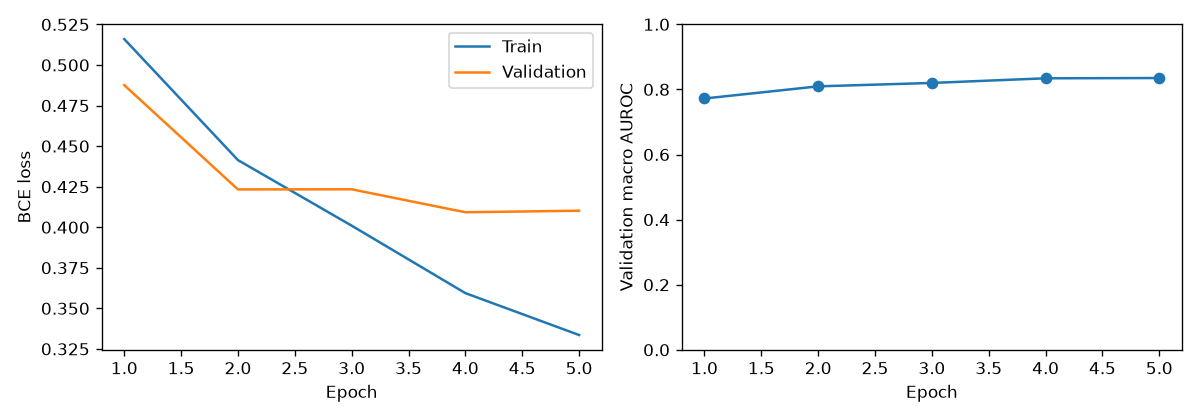

In [12]:
# Report per-class metrics for the restored checkpoint.
_, val_targets, val_probabilities = run_epoch(val_loader)
validation_metrics = classification_metrics(val_targets, val_probabilities)
print(f"Validation metrics (F1 probability threshold: {F1_THRESHOLD:g})")
print(validation_metrics.round(4).to_string())
print(f"Macro AUROC: {validation_metrics['AUROC'].mean():.4f}")
print(f"Macro average precision: {validation_metrics['average_precision'].mean():.4f}")
print(f"Macro F1: {validation_metrics['F1'].mean():.4f}")
validation_metrics.to_csv(run_dir / "validation_metrics.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="BCE loss")
axes[0].legend()
axes[1].plot(history_df["epoch"], history_df["val_macro_auc"], marker="o")
axes[1].set(xlabel="Epoch", ylabel="Validation macro AUROC", ylim=(0, 1))
fig.tight_layout()
fig.savefig(run_dir / "learning_curves.png", dpi=150)
plt.show()

### Optional final test evaluation

Keep `RUN_TEST = False` while choosing the architecture or tuning training.
When those choices are final, set it to `True` in the configuration and run this
cell using the restored best model. AUROC and average precision use probabilities;
per-class F1 uses the configured `F1_THRESHOLD`.

In [13]:
if RUN_TEST:
    test_dataset = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loss, test_targets, test_probabilities = run_epoch(test_loader)
    test_metrics = classification_metrics(test_targets, test_probabilities)
    print(f"Test metrics (F1 probability threshold: {F1_THRESHOLD:g})")
    print(test_metrics.round(4).to_string())
    print(f"Test loss: {test_loss:.4f}; macro AUROC: {test_metrics['AUROC'].mean():.4f}; "
          f"macro AP: {test_metrics['average_precision'].mean():.4f}")
    print(f"Macro F1: {test_metrics['F1'].mean():.4f}")
    test_metrics.to_csv(run_dir / "test_metrics.csv")
else:
    print("Test evaluation skipped. Set RUN_TEST=True only for the final evaluation.")

Test evaluation skipped. Set RUN_TEST=True only for the final evaluation.
